**Bike Image Classification using HOG Features and K-Means**
-In this notebook we will take a folder of bike photos (bicycles, scooters, motorcycles, e-bikes) and automatically group similar-looking bikes together, without telling the computer what any image is.

 What is HOG (Histogram of Oriented Gradients)? -
HOG describes the shape and edges of an object. It looks at small boxes of the image and measures in which direction the edges point (horizontal, vertical, diagonal). A bike has circular wheels, a long frame and handlebars, so its edge directions look very different from a car or a chair. HOG turns these edge directions into a list of numbers.

What is K-Means?-K-Means is an unsupervised machine learning method. "Unsupervised" means we do not give it labels like "scooter" or "motorcycle". We only say "make K groups". It then puts images with similar numbers in the same group.

In [31]:
!pip install numpy pandas matplotlib scikit-image scikit-learn Pillow  

In [35]:
#import the libraries
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from skimage.feature import hog                       # HOG feature extractor
from sklearn.preprocessing import StandardScaler       # brings numbers to the same scale
from sklearn.decomposition import PCA                  # shrinks the number of features
from sklearn.cluster import KMeans                     # the clustering algorithm
from sklearn.metrics import silhouette_score           # measures how good the groups are
 #makes graphs appear inside the notebook instead of in a separate window.
%matplotlib inline   

In [44]:
IMAGE_FOLDER = r"C:\Users\anand\Downloads\Bike"
IMAGE_SIZE = (128, 128)
OUTPUT_FOLDER = "bike_clusters"

**Find all the images**--os.listdir gives the names of all files in the folder. We keep only the files that end with an image extension (.jpg, .png ...) and sorted puts them in a fixed order, so you get the same result every time you run it.

In [46]:
image_files = sorted([f for f in os.listdir(IMAGE_FOLDER)
                      if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp", ".bmp"))])

print("Total images found:", len(image_files))
print("First 3 file names:", image_files[:3])

Total images found: 209
First 3 file names: ['004b3874e2614291c9c3a7755d88762e.jpg', '02cfe7f7468798ac78e6aae80fad2283.jpg', '04f60551d0f6a2173de887a6916294ee.jpg']


**Look at some images**- Here we show the first 12 images in a grid of 3 rows and 4 columns. Notice that the bikes have different sizes, angles and backgrounds, which is what makes this a real, slightly messy dataset.

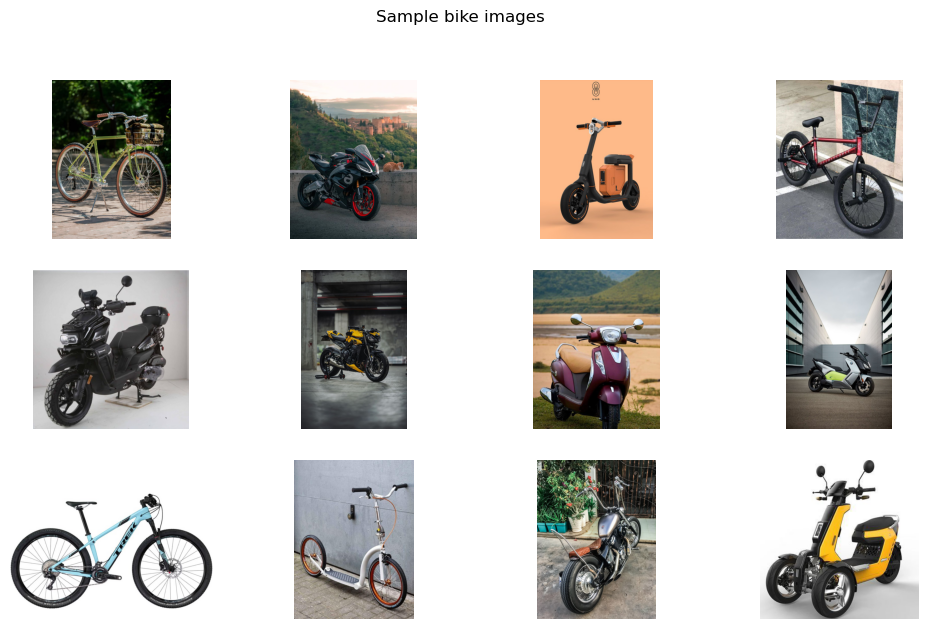

In [52]:
plt.figure(figsize=(12, 7))
for i, name in enumerate(image_files[:12]):
    img = Image.open(os.path.join(IMAGE_FOLDER, name)).convert("RGB")
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")
plt.suptitle("Sample bike images")
plt.show()

**A function to load and prepare one image**

We will do the same 3 things to every image, so we put them in a small function:

1.convert("RGB"): makes sure the image has 3 colour channels (some files are PNG with transparency or palette colours, which would cause errors).

2.resize(IMAGE_SIZE): makes all images 128 x 128.

3.convert("L"): converts to grayscale (black and white). HOG works on edges and shapes, not colours, so removing colour makes it simpler. We divide by 255 so pixel values are between 0 and 1.

In [58]:
def load_gray_image(path):
    img = Image.open(path).convert("RGB")        # make sure it has 3 colour channels
    img = img.resize(IMAGE_SIZE)                 # same size for every image
    gray = np.array(img.convert("L")) / 255.0    # grayscale, values between 0 and 1
    return gray

# test it on the first image
test_img = load_gray_image(os.path.join(IMAGE_FOLDER, image_files[0]))
print("Image shape after preparing:", test_img.shape)

Image shape after preparing: (128, 128)


**What does HOG actually see?**
Let us run HOG on one image and see the result. The hog() function has a few important settings:

1.orientations=9: edge directions are divided into 9 groups (0 to 180 degrees).
2.pixels_per_cell=(8, 8): the image is cut into small cells of 8 x 8 pixels. In each cell HOG counts how many edges point in each of the 9 directions.
3.cells_per_block=(2, 2): cells are grouped into blocks of 2 x 2 cells, and the numbers are normalised inside each block. This makes HOG less sensitive to lighting changes.
visualize=True: also gives us a picture of the HOG, so we can see what it found.
4.How many numbers do we get? The 128 x 128 image has 16 x 16 cells. Blocks of 2 x 2 cells slide across it, giving 15 x 15 = 225 blocks. Each block has 2 x 2 x 9 = 36 numbers. So 225 x 36 = 8100 numbers per image. That list of 8100 numbers is the "fingerprint" of the bike's shape.



Number of HOG features for one image: 8100


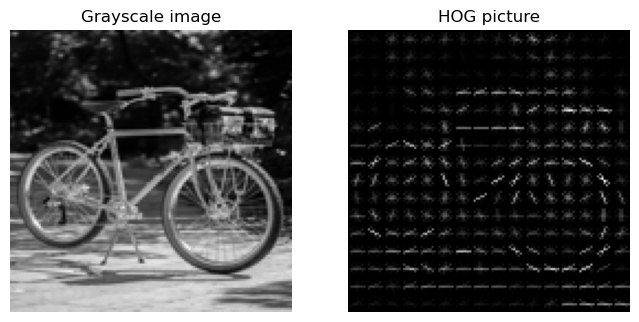

In [62]:
features, hog_image = hog(test_img,
                          orientations=9,
                          pixels_per_cell=(8, 8),
                          cells_per_block=(2, 2),
                          visualize=True)

print("Number of HOG features for one image:", features.shape[0])

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(test_img, cmap="gray")
plt.title("Grayscale image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG picture")
plt.axis("off")
plt.show()

**Extract HOG features for all images**
Now we repeat the same thing for every image and collect the results in a list. At the end we convert the list into a numpy array called X.

X is a table where each row is one image and each column is one HOG number. So its shape will be (number of images, 8100).

We use try / except so that if one file is broken, the code prints a message and continues instead of stopping completely.

all_features = []
valid_files = []

for name in image_files:
    try:
        gray = load_gray_image(os.path.join(IMAGE_FOLDER, name))
        f = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
        all_features.append(f)
        valid_files.append(name)
    except Exception as e:
        print("Skipped", name, "->", e)

X = np.array(all_features)
print("Feature table shape (images, features):", X.shape)

In [68]:
all_features = []
valid_files = []

for name in image_files:
    try:
        gray = load_gray_image(os.path.join(IMAGE_FOLDER, name))
        f = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
        all_features.append(f)
        valid_files.append(name)
    except Exception as e:
        print("Skipped", name, "->", e)

X = np.array(all_features)
print("Feature table shape (images, features):", X.shape)

Feature table shape (images, features): (209, 8100)


**Scale the features and reduce them with PCA**
8,100 numbers per image is a lot, and many of them carry almost the same information. Two things help:

1.StandardScaler: shifts and scales every column so that it has an average of 0 and similar spread. K-Means uses distances, so all columns should be on the same scale.
2.PCA (Principal Component Analysis): finds the most important combinations of the 8,100 numbers and keeps only the top 50. This makes K-Means faster and usually cleaner, because noise is removed.

In [71]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Shape before PCA:", X_scaled.shape)
print("Shape after PCA :", X_pca.shape)
print("Information kept: {:.1f}%".format(pca.explained_variance_ratio_.sum() * 100))

Shape before PCA: (209, 8100)
Shape after PCA : (209, 50)
Information kept: 52.5%


**How many groups (K) should we make?**--
K-Means needs us to choose K, the number of groups. Since we do not know the best number, we try K = 2 to 10 and measure two things:

1.Inertia (Elbow method): how tightly packed the images are inside their groups. It always goes down as K increases, so we look for the elbow: the point where the curve stops dropping quickly.
2.Silhouette score: a number from -1 to 1 that tells how well separated the groups are. Higher is better. Values close to 0 mean the groups overlap.

k_values = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertias.append(km.inertia_)
    score = silhouette_score(X_pca, km.labels_)
    silhouettes.append(score)
    print("k =", k, "| inertia =", round(km.inertia_), "| silhouette =", round(score, 3))

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow method (lower is tighter)")
plt.xlabel("Number of groups (K)")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouettes, marker="o", color="green")
plt.title("Silhouette score (higher is better)")
plt.xlabel("Number of groups (K)")
plt.ylabel("Silhouette score")

plt.tight_layout()
plt.show()

k = 2 | inertia = 797744 | silhouette = 0.146
k = 3 | inertia = 767006 | silhouette = 0.068
k = 4 | inertia = 742263 | silhouette = 0.037
k = 5 | inertia = 720380 | silhouette = 0.076
k = 6 | inertia = 707324 | silhouette = 0.043
k = 7 | inertia = 691315 | silhouette = 0.037
k = 8 | inertia = 675502 | silhouette = 0.042
k = 9 | inertia = 654655 | silhouette = 0.055
k = 10 | inertia = 656678 | silhouette = 0.042


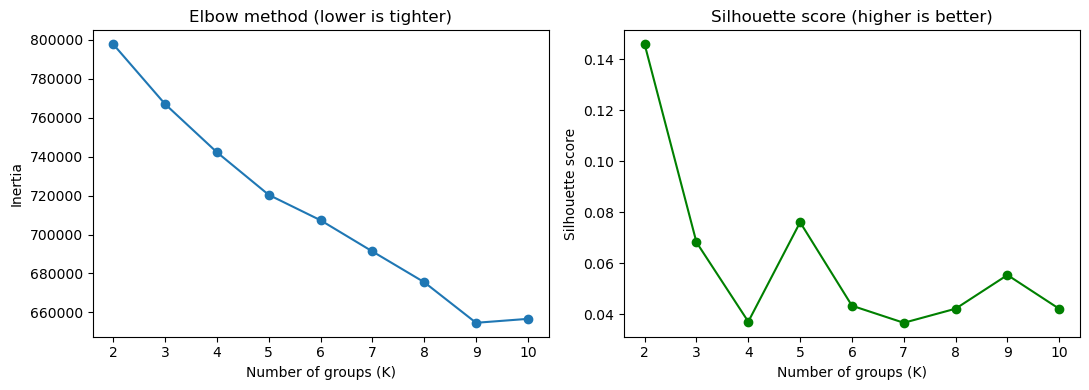

In [79]:
k_values = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertias.append(km.inertia_)
    score = silhouette_score(X_pca, km.labels_)
    silhouettes.append(score)
    print("k =", k, "| inertia =", round(km.inertia_), "| silhouette =", round(score, 3))

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow method (lower is tighter)")
plt.xlabel("Number of groups (K)")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouettes, marker="o", color="green")
plt.title("Silhouette score (higher is better)")
plt.xlabel("Number of groups (K)")
plt.ylabel("Silhouette score")

plt.tight_layout()
plt.show()

**Run K-Means with chosen K**-Now we pick K and run the final clustering.

1.KMeans(n_clusters=K): create the model that will make K groups.
2.random_state=42: K-Means starts from random centres. Fixing the random seed gives the same result every time you run the notebook.
3.n_init=10: run the algorithm 10 times with different starting points and keep the best result.
4.fit_predict: learns the groups and gives back a group number (label) for each image.

In [82]:
K = 5

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_pca)

result = pd.DataFrame({"image": valid_files, "cluster": labels})

print("Number of images in each cluster:")
print(result["cluster"].value_counts().sort_index())

result.head(10)

Number of images in each cluster:
0     18
1    108
2     44
3     19
4     20
Name: cluster, dtype: int64


,image,cluster
0,004b3874e2614291c9c3a7755d88762e.jpg,2
1,02cfe7f7468798ac78e6aae80fad2283.jpg,1
2,04f60551d0f6a2173de887a6916294ee.jpg,3
3,050644bebaaeb2b4d60e154887887538.jpg,1
4,05221d5b2424d00e64dfd5cc7ebf7f31.jpg,1
5,0560c4b872358340c396c0763261e1b9.jpg,1
6,05d867c12f19355d66e3b4c3b4f50a00.jpg,1
7,0663a68a5b4807a2aed57dcd7a651245.jpg,1
8,06a9558dbd001328073f7490be8c9831.jpg,4
9,0706be997dd61c8613eeeddeabb8ea48.jpg,2


**Look at now in every group**--We show up to 10 images from each cluster. Look at them and think: what do the bikes in this group have in common?

HOG groups by shape and edge pattern, so images with a similar outline, viewing angle and background tend to land together. When we ran this on the 209 images, we saw groups such as: bikes photographed on a plain white background, bikes in studio or grey backgrounds, and bikes photographed outdoors with trees, roads or buildings behind them. Scooters and bicycles were mixed in some groups, because HOG is sensitive to how the photo is taken, not only to what the vehicle is.

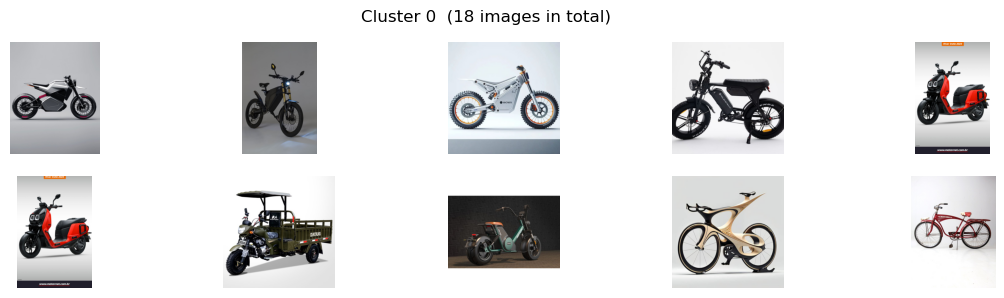

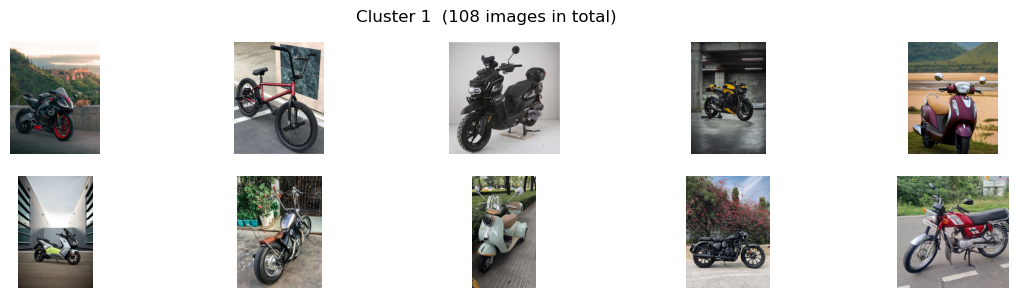

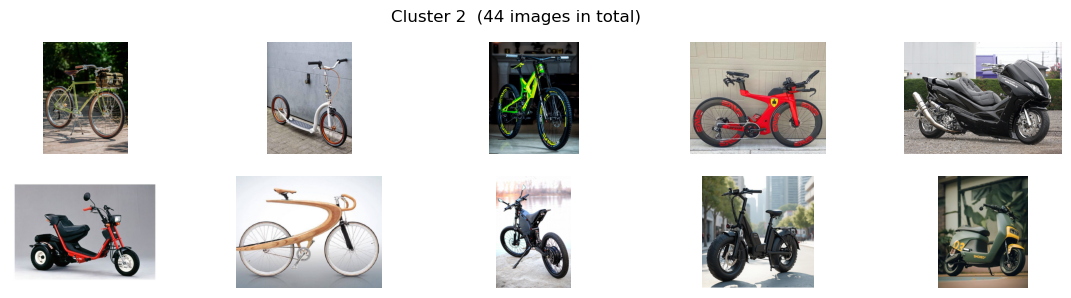

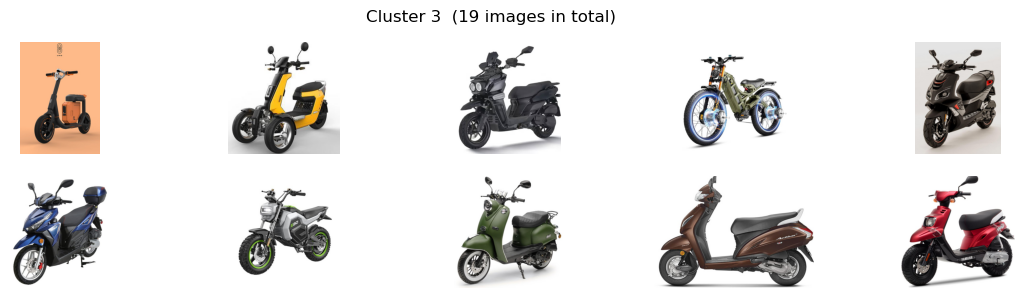

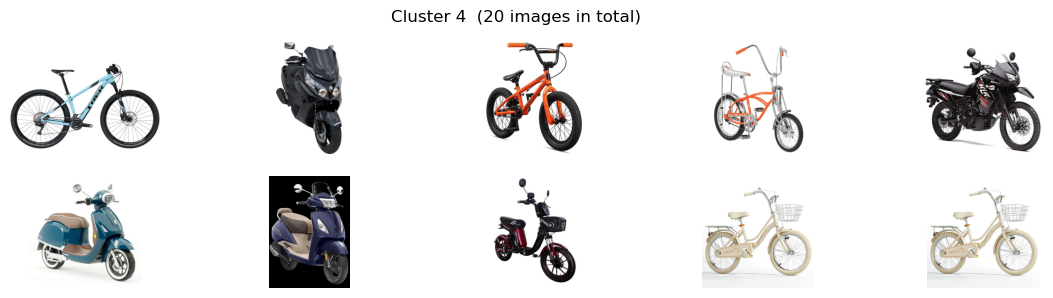

In [85]:
for c in range(K):
    members = result[result["cluster"] == c]["image"].tolist()
    show = members[:10]

    plt.figure(figsize=(14, 3.2))
    for i, name in enumerate(show):
        img = Image.open(os.path.join(IMAGE_FOLDER, name)).convert("RGB")
        plt.subplot(2, 5, i + 1)
        plt.imshow(img)
        plt.axis("off")
    plt.suptitle("Cluster " + str(c) + "  (" + str(len(members)) + " images in total)")
    plt.show()

In [87]:
#ave the groups into folders
if os.path.exists(OUTPUT_FOLDER):
    shutil.rmtree(OUTPUT_FOLDER)        # remove an old result so we start clean
os.makedirs(OUTPUT_FOLDER)

for name, c in zip(result["image"], result["cluster"]):
    folder = os.path.join(OUTPUT_FOLDER, "cluster_" + str(c))
    os.makedirs(folder, exist_ok=True)
    shutil.copy(os.path.join(IMAGE_FOLDER, name), os.path.join(folder, name))

result.to_csv(os.path.join(OUTPUT_FOLDER, "cluster_assignments.csv"), index=False)
print("Saved", len(result), "images into", K, "folders inside '" + OUTPUT_FOLDER + "'.")

Saved 209 images into 5 folders inside 'bike_clusters'.


**Put a NEW bike image into the right group**--This is what makes it a "classifier". For a new image we must do exactly the same steps as for the training images, using the same scaler and pca we already fitted.

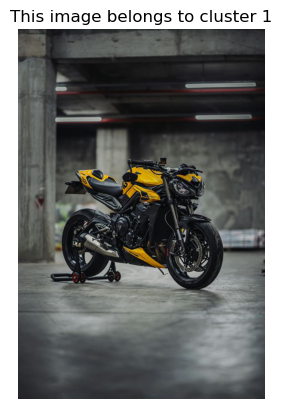

In [90]:
def predict_cluster(path):
    gray = load_gray_image(path)
    f = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    f = scaler.transform([f])
    f = pca.transform(f)
    return int(kmeans.predict(f)[0])

new_image_path = os.path.join(IMAGE_FOLDER, image_files[5])      # change this to your own image
cluster_id = predict_cluster(new_image_path)

plt.imshow(Image.open(new_image_path).convert("RGB"))
plt.title("This image belongs to cluster " + str(cluster_id))
plt.axis("off")
plt.show()

**Summary**

Developed an unsupervised image-grouping system for 209 bike photos using Python. Images were resized and converted to grayscale, then HOG features captured shape and edge patterns. PCA reduced dimensions, and K-Means clustering grouped similar bikes, with K chosen using elbow and silhouette analysis. Results were visualized and saved into folders.  


In [ ]:
**What we did**

1.Loaded the bike images and made them all the same size and grayscale
2.Turned each image into 8,100 HOG numbers describing its shape
3.Compressed these numbers to 50 with PCA
4.Used K-Means to build K groups of similar-looking bikes
5.Looked at the groups, saved them into folders and built a function for new images